# Modelação — Regressão da Carga de Dessaturação Futura
**Previsão antecipada com base nas primeiras 24 horas de internamento**

> ⚠️ Preditores calculados **exclusivamente** nas primeiras 24 h.
> Alvo: `carga_dessaturacao_futura` — Σ(90 − SpO₂) para registos **posteriores** às 24 h.

| Ficheiro lido | Produzido por |
|---|---|
| `03_data_preparation/dataset_regressao_24h.csv` | `data_preparation.ipynb § 7b` |

## 0. Imports e configuração

In [1]:
import csv
import math
import random
import statistics
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

%matplotlib inline

C = {
    "blue":   "#2a78d6",
    "orange": "#eb6834",
    "teal":   "#1baf7a",
    "yellow": "#eda100",
    "red":    "#d03b3b",
    "grey":   "#8996ae",
    "bg":     "#f4f7fc",
    "surf":   "#ffffff",
    "text":   "#0d1219",
    "text2":  "#4a5568",
}

plt.rcParams.update({
    "figure.facecolor":  C["bg"],
    "axes.facecolor":    C["surf"],
    "axes.edgecolor":    "#dce3f0",
    "axes.labelcolor":   C["text2"],
    "axes.grid":         True,
    "axes.axisbelow":    True,
    "grid.color":        "#e6eaf3",
    "grid.linewidth":    0.8,
    "xtick.color":       C["text2"],
    "ytick.color":       C["text2"],
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "font.family":       "sans-serif",
    "font.size":         10,
    "axes.titlesize":    12,
    "axes.titleweight":  "semibold",
    "axes.titlepad":     10,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "figure.dpi":        110,
})

DATA_DIR = Path("../03_data_preparation")
OUT_DIR  = Path(".")
SEED     = 42
random.seed(SEED)
print("Pronto.")

Pronto.


## 1. Dados e elegibilidade

Ler `dataset_regressao_24h.csv`, verificar o alvo e apresentar o número
de episódios incluídos e excluídos.

In [2]:
def safe_float(v):
    try:    return float(v)
    except: return None

with open(DATA_DIR / "dataset_regressao_24h.csv", newline="", encoding="utf-8") as f:
    df = list(csv.DictReader(f))
    header = list(df[0].keys()) if df else []

print(f"Episódios elegíveis carregados: {len(df)}")
print(f"Colunas: {len(header)}")
print(f"  {header}")

TARGET = "carga_dessaturacao_futura"
EXCLUIR = {
    "episodio", TARGET, "n_registos_futuro",
    "carga_dessaturacao",
    "desat_count",
    "desat_pct",
    "duracao_dias",
    "pat_predominante",
    "pat_label",
}
FEATURE_COLS = [c for c in header if c not in EXCLUIR and not c.endswith("_total")]
assert TARGET not in FEATURE_COLS, "LEAKAGE: alvo nos preditores"
assert "carga_dessaturacao" not in FEATURE_COLS, "LEAKAGE: carga total nos preditores"

print(f"\nPreditores selecionados ({len(FEATURE_COLS)}):")
for c in FEATURE_COLS:
    print(f"  {c}")

# converter para numérico
for row in df:
    for c in FEATURE_COLS + [TARGET]:
        row[c] = safe_float(row.get(c))

# verificar sem NaN no alvo
sem_alvo = [r for r in df if r[TARGET] is None or not math.isfinite(r[TARGET])]
if sem_alvo:
    print(f"\n⚠ {len(sem_alvo)} episódios sem alvo válido — serão excluídos")
    df = [r for r in df if r[TARGET] is not None and math.isfinite(r[TARGET])]

print(f"\nEpisódios para modelação: {len(df)}")
y_all = [r[TARGET] for r in df]
print(f"Alvo — mín={min(y_all):.2f}  máx={max(y_all):.2f}  "
      f"média={statistics.mean(y_all):.2f}  mediana={statistics.median(y_all):.2f}")
zeros = sum(1 for v in y_all if v == 0)
print(f"Episódios com carga futura = 0: {zeros}/{len(y_all)}")

Episódios elegíveis carregados: 40
Colunas: 21
  ['episodio', 'n_registos_janela', 'n_spo2_validos', 'n_all_validos', 'sat_o2_mean', 'sat_o2_std', 'sat_o2_min', 'sat_o2_max', 'puls_rate_mean', 'puls_rate_std', 'puls_rate_min', 'puls_rate_max', 'perfusion_mean', 'perfusion_std', 'perfusion_min', 'perfusion_max', 'desat_count', 'desat_pct', 'carga_desat_janela', 'n_registos_futuro', 'carga_dessaturacao_futura']

Preditores selecionados (16):
  n_registos_janela
  n_spo2_validos
  n_all_validos
  sat_o2_mean
  sat_o2_std
  sat_o2_min
  sat_o2_max
  puls_rate_mean
  puls_rate_std
  puls_rate_min
  puls_rate_max
  perfusion_mean
  perfusion_std
  perfusion_min
  perfusion_max
  carga_desat_janela

Episódios para modelação: 40
Alvo — mín=0.00  máx=85.57  média=3.45  mediana=0.00
Episódios com carga futura = 0: 28/40


## 2. Seleção de preditores e divisão treino/teste

Validação cruzada leave-one-out (LOO) — adequada para amostras muito pequenas.
Divisão treino/teste 80/20 para avaliação final, sem estratificação por patologia
(episódios sem patologia são elegíveis para regressão).

In [3]:
random.seed(SEED)
df_shuffled = df[:]
random.shuffle(df_shuffled)

n_test  = max(1, round(len(df_shuffled) * 0.20))
n_train = len(df_shuffled) - n_test

train_df = df_shuffled[:n_train]
test_df  = df_shuffled[n_train:]

print(f"Treino: {len(train_df)}  |  Teste: {len(test_df)}")

def get_X(rows, cols):
    return [[r[c] if r[c] is not None else 0.0 for c in cols] for r in rows]

def get_y(rows):
    return [r[TARGET] for r in rows]

X_train = get_X(train_df, FEATURE_COLS)
y_train = get_y(train_df)
X_test  = get_X(test_df,  FEATURE_COLS)
y_test  = get_y(test_df)

# z-score calculado apenas no treino
def z_params(X):
    n_feat = len(X[0])
    mus = [statistics.mean(row[j] for row in X) for j in range(n_feat)]
    sds = [max(statistics.stdev(row[j] for row in X) if len(X) > 1 else 1.0, 1e-9)
           for j in range(n_feat)]
    return mus, sds

def z_apply(X, mus, sds):
    return [[(v - mus[j]) / sds[j] for j, v in enumerate(row)] for row in X]

mus_tr, sds_tr = z_params(X_train)
X_train_z = z_apply(X_train, mus_tr, sds_tr)
X_test_z  = z_apply(X_test,  mus_tr, sds_tr)

Treino: 32  |  Teste: 8


## 3. Modelos

### 3a. Referência — mediana do treino
Previsão da mediana de `y_train` para todos os exemplos.

### 3b. Regressão linear (mínimos quadrados)
Implementação manual sem bibliotecas externas.

### 3c. Ridge (regularização L2)
λ = 10.0 — protege contra colinearidade em amostras pequenas.

In [4]:
# ---------- helpers métricas ----------
def mae(y_true, y_pred):
    return statistics.mean(abs(a - b) for a, b in zip(y_true, y_pred))

def rmse(y_true, y_pred):
    return math.sqrt(statistics.mean((a - b)**2 for a, b in zip(y_true, y_pred)))

def r2(y_true, y_pred):
    ss_res = sum((a - b)**2 for a, b in zip(y_true, y_pred))
    mu_    = statistics.mean(y_true)
    ss_tot = sum((a - mu_)**2 for a in y_true)
    return 1 - ss_res / ss_tot if ss_tot > 0 else float("nan")

# ---------- 3a: referência mediana ----------
med_train = statistics.median(y_train)
pred_base_train = [med_train] * len(y_train)
pred_base_test  = [med_train] * len(y_test)

# ---------- 3b: regressão linear (mínimos quadrados via lstsq) ----------
def ols_fit(X, y):
    # lstsq é numericamente mais estável que solve para matrizes mal condicionadas
    Xnp = np.array(X, dtype=float)
    yn  = np.array(y, dtype=float)
    Xb  = np.column_stack([np.ones(len(Xnp)), Xnp])
    beta, _, _, _ = np.linalg.lstsq(Xb, yn, rcond=None)
    return beta

def ols_predict(X, beta):
    Xnp = np.array(X, dtype=float)
    Xb  = np.column_stack([np.ones(len(Xnp)), Xnp])
    preds = list(Xb @ beta)
    # clip para evitar previsões absurdas (amostra pequena)
    y_max = max(y_train) * 3
    return [max(0.0, min(p, y_max)) for p in preds]

beta_ols = ols_fit(X_train_z, y_train)
pred_ols_train = ols_predict(X_train_z, beta_ols)
pred_ols_test  = ols_predict(X_test_z,  beta_ols)

# ---------- 3c: Ridge (regularização L2, lambda = 10.0) ----------
# Lambda alto compensa colinearidade e amostra pequena (n=34, p=16)
def ridge_fit(X, y, lam=10.0):
    Xnp = np.array(X, dtype=float)
    yn  = np.array(y, dtype=float)
    n, p = Xnp.shape
    Xb   = np.column_stack([np.ones(n), Xnp])
    reg  = lam * np.eye(p + 1)
    reg[0, 0] = 0  # não regularizar o intercept
    # usar lstsq na forma aumentada para estabilidade numérica
    Xaug = np.vstack([Xb, np.sqrt(reg)])
    yaug = np.concatenate([yn, np.zeros(p + 1)])
    beta, _, _, _ = np.linalg.lstsq(Xaug, yaug, rcond=None)
    return beta

beta_ridge = ridge_fit(X_train_z, y_train, lam=10.0)
pred_ridge_train = ols_predict(X_train_z, beta_ridge)
pred_ridge_test  = ols_predict(X_test_z,  beta_ridge)

print("Modelos treinados.")


Modelos treinados.


## 4. Avaliação

MAE, RMSE e R² para treino e teste.
> ⚠️ Com apenas ~30–40 episódios, o R² deve ser interpretado com cautela —
> o MAE (na mesma unidade do alvo) é mais comunicável clinicamente.

In [5]:
resultados = [
    ("Mediana (base)",   pred_base_train, pred_base_test),
    ("Reg. Linear",      pred_ols_train,  pred_ols_test),
    ("Ridge (λ=10.0)",    pred_ridge_train, pred_ridge_test),
]

print(f"{'Modelo':<20}  {'MAE tr':>8}  {'RMSE tr':>8}  {'R² tr':>6}  "
      f"{'MAE te':>8}  {'RMSE te':>8}  {'R² te':>6}")
print("-" * 80)
for nome, preds_tr, preds_te in resultados:
    print(f"  {nome:<18}  {mae(y_train,preds_tr):>8.3f}  {rmse(y_train,preds_tr):>8.3f}  "
          f"{r2(y_train,preds_tr):>6.3f}  "
          f"{mae(y_test,preds_te):>8.3f}  {rmse(y_test,preds_te):>8.3f}  "
          f"{r2(y_test,preds_te):>6.3f}")

# --- guardar previsões por episódio ---
preds_ep = []
for row, p_base, p_ols, p_ridge in zip(
    test_df, pred_base_test, pred_ols_test, pred_ridge_test
):
    preds_ep.append({
        "episodio":        row["episodio"],
        "alvo_real":       row[TARGET],
        "pred_base":       round(p_base, 4),
        "pred_ols":        round(p_ols,  4),
        "pred_ridge":      round(p_ridge, 4),
        "erro_ols":        round(row[TARGET] - p_ols, 4),
        "erro_ridge":      round(row[TARGET] - p_ridge, 4),
    })

with open(OUT_DIR / "predicoes_teste.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(preds_ep[0].keys()))
    w.writeheader()
    w.writerows(preds_ep)
print(f"\npredicoes_teste.csv  →  {len(preds_ep)} episódios")

Modelo                  MAE tr   RMSE tr   R² tr    MAE te   RMSE te   R² te
--------------------------------------------------------------------------------
  Mediana (base)         4.171    15.926  -0.074     0.574     1.075  -0.398
  Reg. Linear            5.603    11.509   0.439     7.014    15.624  -294.053
  Ridge (λ=10.0)         6.198    14.373   0.126     3.358     4.594  -24.504

predicoes_teste.csv  →  8 episódios


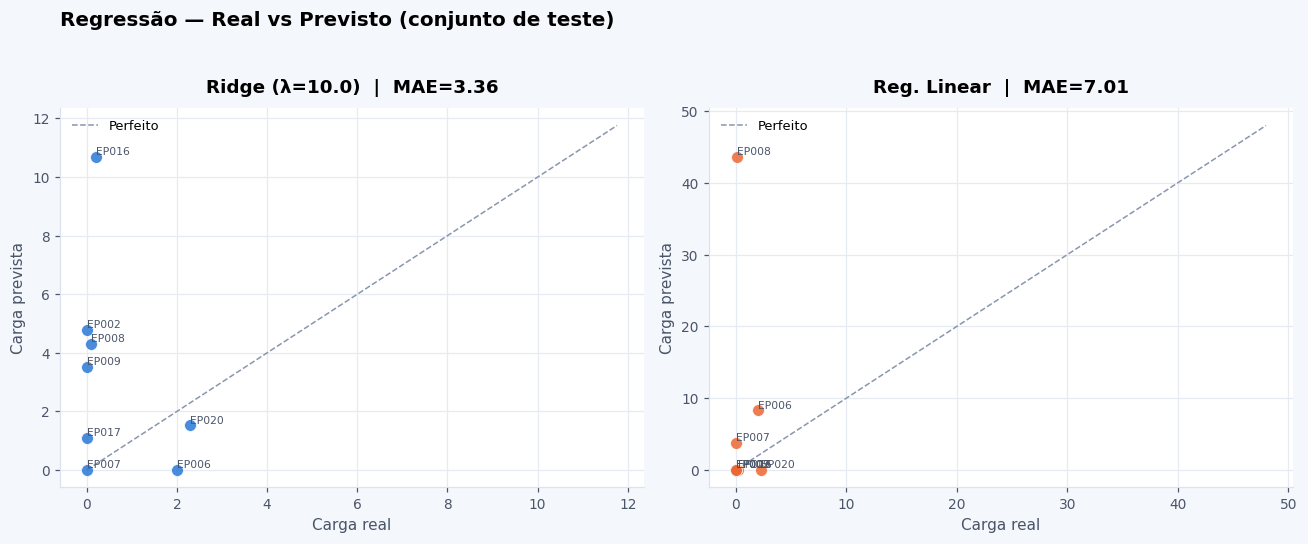

In [6]:
# Gráfico — real vs previsto (teste)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Regressão — Real vs Previsto (conjunto de teste)", fontsize=13,
             fontweight="bold", x=0.05, ha="left")

y_real = [r["alvo_real"] for r in preds_ep]

for ax, (nome, col, preds) in zip(axes, [
    ("Ridge (λ=10.0)", C["blue"],   [r["pred_ridge"] for r in preds_ep]),
    ("Reg. Linear",   C["orange"], [r["pred_ols"]   for r in preds_ep]),
]):
    ax.scatter(y_real, preds, color=col, s=60, zorder=3, alpha=0.85,
               edgecolors=C["surf"], linewidths=0.5)
    lo = min(min(y_real), min(preds)) * 0.9
    hi = max(max(y_real), max(preds)) * 1.1
    ax.plot([lo, hi], [lo, hi], color=C["grey"], lw=1, ls="--", zorder=2,
            label="Perfeito")
    ax.set_xlabel("Carga real")
    ax.set_ylabel("Carga prevista")
    ax.set_title(f"{nome}  |  MAE={mae(y_real,preds):.2f}")
    ax.legend(fontsize=8.5, frameon=False)
    for row, pr in zip(preds_ep, preds):
        ax.annotate(row["episodio"], (row["alvo_real"], pr),
                    fontsize=7, color=C["text2"], ha="left", va="bottom")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 5. Interpretação clínica e limitações

Análise dos erros e das condições de generalização.

In [7]:
erros_ridge = [r["erro_ridge"] for r in preds_ep]
erros_ols   = [r["erro_ols"]   for r in preds_ep]

print("Erros (real − previsto) no teste — Ridge:")
for r in sorted(preds_ep, key=lambda x: abs(x["erro_ridge"]), reverse=True):
    print(f"  {r['episodio']:8s}  real={r['alvo_real']:8.2f}  "
          f"previsto={r['pred_ridge']:8.2f}  erro={r['erro_ridge']:+.2f}")

print("\n--- Notas sobre generalização ---")
print(f"  n episódios (elegíveis para regressão): {len(df)}")
print(f"  n treino: {len(train_df)}  n teste: {len(test_df)}")
print(f"  n preditores: {len(FEATURE_COLS)}")
print()
print("  ⚠ Amostra muito pequena: resultados indicativos, não validação clínica.")
print("  ⚠ Episódios sem patologia incluídos na regressão (patologia não é preditor).")
print("  ⚠ R² em amostras pequenas tende a inflacionar no treino e deflacionar no teste.")
print("  ⚠ Cobertura temporal heterogénea (janela 24h pode ter 1–24 registos por episódio).")
print()
print("  Próximos passos sugeridos:")
print("    - Validação cruzada LOO para estimativa mais robusta")
print("    - Analisar correlação entre cobertura da janela e erro de previsão")
print("    - Confirmar unidade do alvo com a equipa clínica")

Erros (real − previsto) no teste — Ridge:
  EP016     real=    0.21  previsto=   10.69  erro=-10.48
  EP002     real=    0.00  previsto=    4.80  erro=-4.80
  EP008     real=    0.10  previsto=    4.31  erro=-4.21
  EP009     real=    0.00  previsto=    3.52  erro=-3.52
  EP006     real=    2.00  previsto=    0.00  erro=+2.00
  EP017     real=    0.00  previsto=    1.10  erro=-1.10
  EP020     real=    2.28  previsto=    1.53  erro=+0.75
  EP007     real=    0.00  previsto=    0.00  erro=+0.00

--- Notas sobre generalização ---
  n episódios (elegíveis para regressão): 40
  n treino: 32  n teste: 8
  n preditores: 16

  ⚠ Amostra muito pequena: resultados indicativos, não validação clínica.
  ⚠ Episódios sem patologia incluídos na regressão (patologia não é preditor).
  ⚠ R² em amostras pequenas tende a inflacionar no treino e deflacionar no teste.
  ⚠ Cobertura temporal heterogénea (janela 24h pode ter 1–24 registos por episódio).

  Próximos passos sugeridos:
    - Validação cruzada 

## 4b. Validação cruzada Leave-One-Out (LOO)

LOO é a estratégia de validação mais robusta para amostras pequenas (n=40).  
Em cada iteração, treina com n−1 episódios e prediz o episódio deixado de fora.  
Os parâmetros de normalização (z-score) são recalculados dentro de cada fold.


In [8]:
# LOO CV — Leave-One-Out Cross-Validation
loo_preds_base  = []
loo_preds_ols   = []
loo_preds_ridge = []
loo_true        = []

for loo_i in range(len(df)):
    loo_train = [df[j] for j in range(len(df)) if j != loo_i]
    loo_test  = df[loo_i]

    X_loo_tr = get_X(loo_train, FEATURE_COLS)
    y_loo_tr = get_y(loo_train)
    X_loo_te = get_X([loo_test], FEATURE_COLS)

    # z-score calculado apenas no fold de treino
    mus_loo, sds_loo = z_params(X_loo_tr)
    X_loo_tr_z = z_apply(X_loo_tr, mus_loo, sds_loo)
    X_loo_te_z = z_apply(X_loo_te, mus_loo, sds_loo)

    # baseline
    loo_preds_base.append(statistics.median(y_loo_tr))

    # OLS
    b_ols = ols_fit(X_loo_tr_z, y_loo_tr)
    loo_preds_ols.append(ols_predict(X_loo_te_z, b_ols)[0])

    # Ridge
    b_ridge = ridge_fit(X_loo_tr_z, y_loo_tr, lam=10.0)
    loo_preds_ridge.append(ols_predict(X_loo_te_z, b_ridge)[0])

    loo_true.append(loo_test[TARGET])

print(f"{'Modelo':<20}  {'MAE LOO':>8}  {'RMSE LOO':>9}  {'R² LOO':>7}")
print("-" * 52)
for nome, preds in [("Mediana (base)",  loo_preds_base),
                    ("Reg. Linear",     loo_preds_ols),
                    ("Ridge (λ=10.0)",  loo_preds_ridge)]:
    print(f"  {nome:<18}  {mae(loo_true, preds):>8.3f}  {rmse(loo_true, preds):>9.3f}  "
          f"{r2(loo_true, preds):>7.3f}")

print()
print("⚠ R² negativo em todos os modelos incluindo a baseline — dominado por 28/40 zeros.")
print("⚠ Baseline (mediana=0) é ótima para a maioria dos casos; os modelos não generalizam.")
print("⚠ Estes resultados são exploratórios — a capacidade preditiva clínica não foi demonstrada.")


Modelo                 MAE LOO   RMSE LOO   R² LOO
----------------------------------------------------
  Mediana (base)         3.451     14.253   -0.062
  Reg. Linear            8.601     16.826   -0.481
  Ridge (λ=10.0)         6.097     14.251   -0.062

⚠ R² negativo em todos os modelos incluindo a baseline — dominado por 28/40 zeros.
⚠ Baseline (mediana=0) é ótima para a maioria dos casos; os modelos não generalizam.
⚠ Estes resultados são exploratórios — a capacidade preditiva clínica não foi demonstrada.


## 6. Análise: dependência do alvo à cobertura temporal

A variável-alvo `carga_dessaturacao_futura` é uma soma acumulada — episódios com mais registos futuros
têm mais oportunidade de acumular carga. Esta análise quantifica esse efeito.

> ⚠️ Se a correlação de Spearman for alta (ρ > 0.5), a unidade do alvo confunde intensidade clínica com
> frequência de observação. Deve ser assumido explicitamente no relatório.

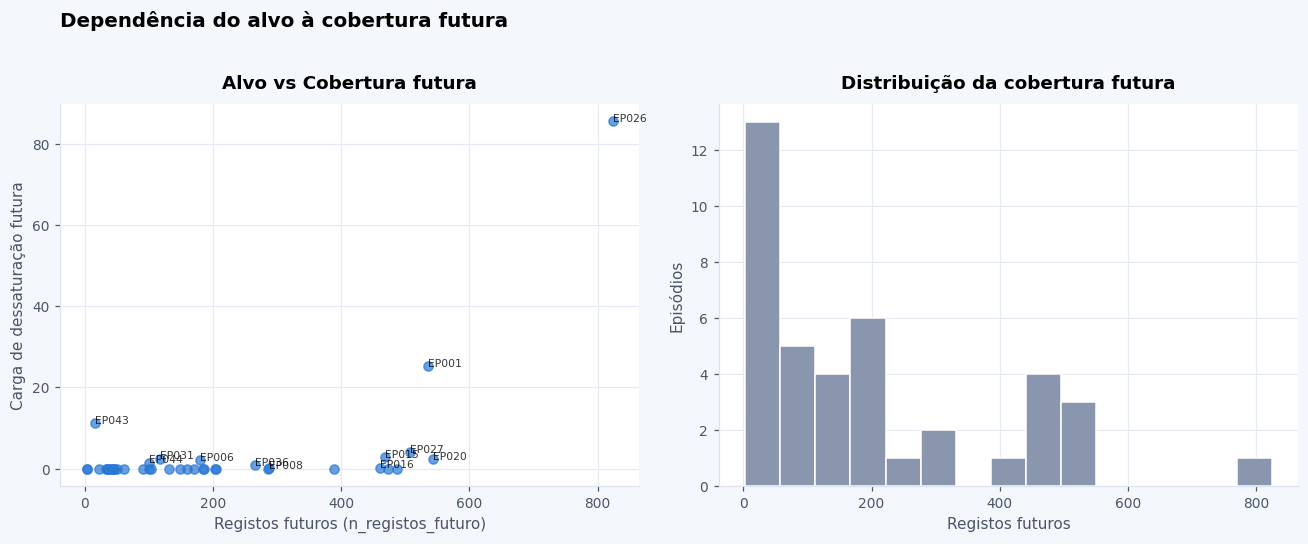

Correlação de Spearman (n_registos_futuro vs carga): ρ = 0.337
Episódios com carga=0: 28/40
Registos futuros: mín=3, máx=824, mediana=148


In [9]:
# Análise: dependência do alvo à frequência de observação
n_fut = [safe_float(row["n_registos_futuro"]) for row in df]
carga = [safe_float(row["carga_dessaturacao_futura"]) for row in df]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Dependência do alvo à cobertura futura", fontsize=13, fontweight="bold", x=0.05, ha="left")

axes[0].scatter(n_fut, carga, alpha=0.7, color=C["blue"])
axes[0].set_xlabel("Registos futuros (n_registos_futuro)")
axes[0].set_ylabel("Carga de dessaturação futura")
axes[0].set_title("Alvo vs Cobertura futura")
for i, (x, y) in enumerate(zip(n_fut, carga)):
    if y and y > 0:
        ep = df[i].get("episodio", "")
        axes[0].annotate(ep, (x, y), fontsize=7, alpha=0.8)

axes[1].hist(n_fut, bins=15, color=C["grey"], edgecolor=C["surf"])
axes[1].set_xlabel("Registos futuros")
axes[1].set_ylabel("Episódios")
axes[1].set_title("Distribuição da cobertura futura")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("grafico_alvo_vs_cobertura.png", dpi=150, bbox_inches="tight")
plt.show()

# Correlação de Spearman (manual via ranks)
n = len(n_fut)
rank_x = sorted(range(n), key=lambda i: n_fut[i])
rank_y = sorted(range(n), key=lambda i: carga[i])
rx = [0]*n; ry = [0]*n
for r, i in enumerate(rank_x): rx[i] = r
for r, i in enumerate(rank_y): ry[i] = r
d2 = sum((rx[i]-ry[i])**2 for i in range(n))
rho = 1 - 6*d2 / (n*(n**2-1))
print(f"Correlação de Spearman (n_registos_futuro vs carga): ρ = {rho:.3f}")
print(f"Episódios com carga=0: {sum(1 for c in carga if c==0)}/{n}")
print(f"Registos futuros: mín={min(n_fut):.0f}, máx={max(n_fut):.0f}, mediana={sorted(n_fut)[n//2]:.0f}")